# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import RSC11Dataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/RSC11/data"
}
dataset = RSC11Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1232


## Show images from the dataset

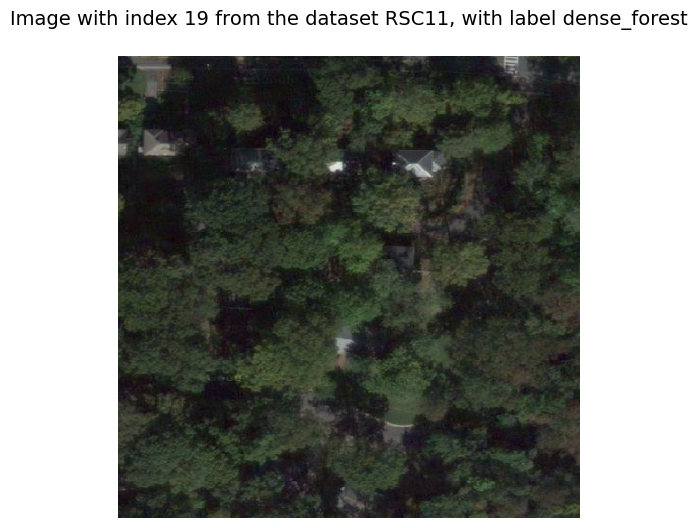

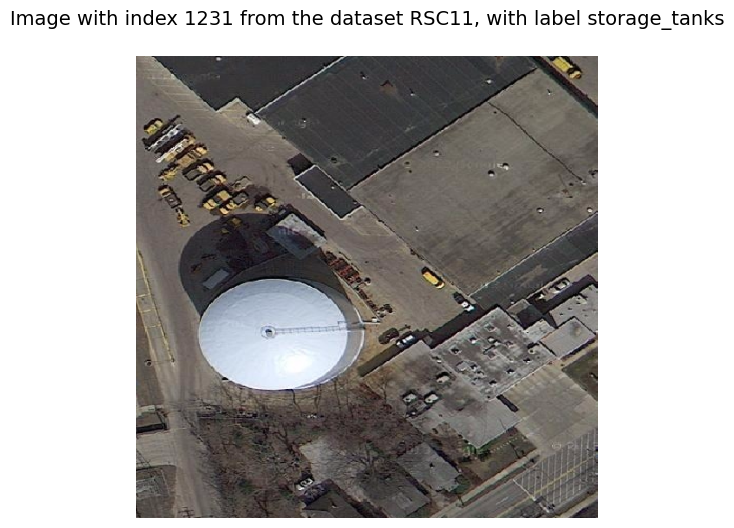

In [7]:
fig1 = dataset.show_image(19)
fig1 = dataset.show_image(1231);

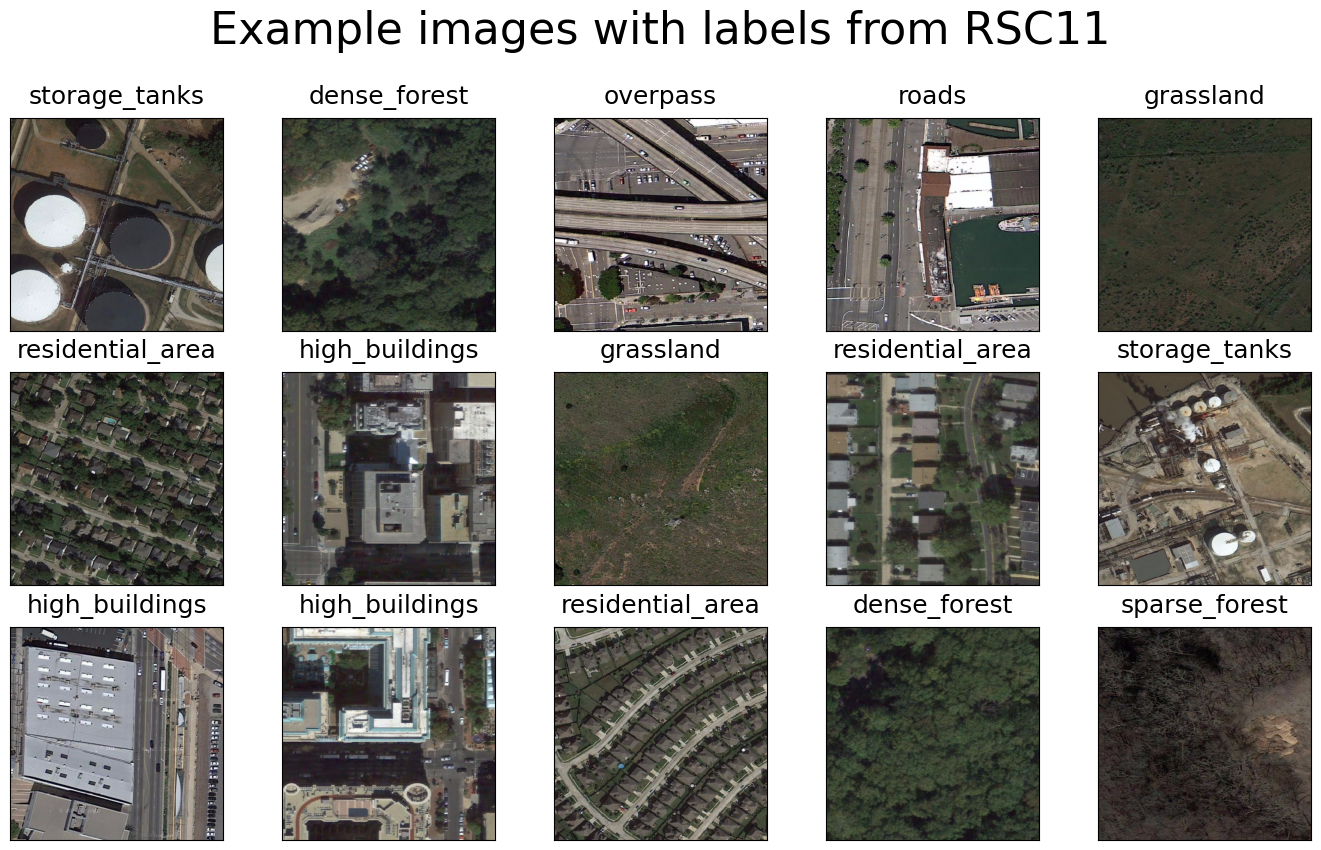

In [8]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [6]:
dataset.data_distribution_table()

,Label,Count
0,roads,142
1,residential_area,140
2,dense_forest,138
3,sparse_forest,112
4,low_buildings,110
5,high_buildings,108
6,overpass,106
7,storage_tanks,106
8,grassland,102
9,harbor,88


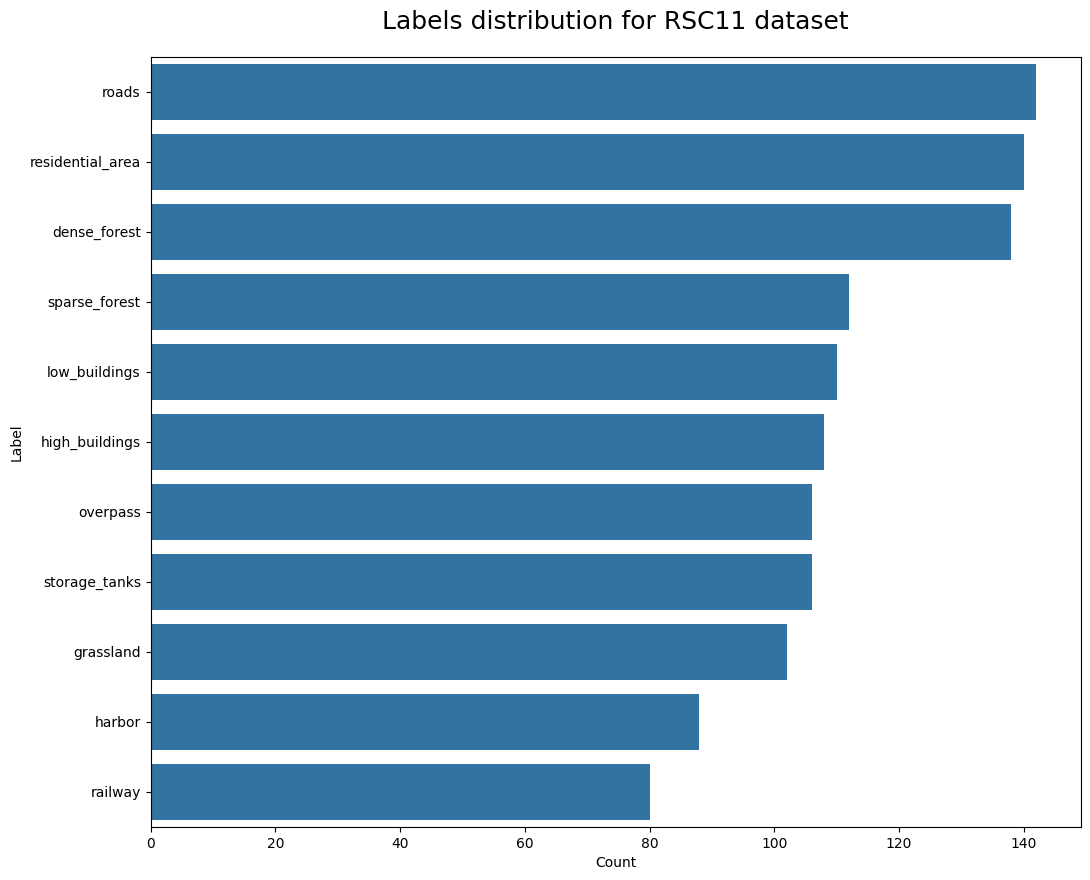

In [7]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/RSC11/data",
    "csv_file": "./data/RSC11/rsc11_train.csv",
}

train_dataset = RSC11Dataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/RSC11/data",
    "csv_file": "./data/RSC11/rsc11_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = RSC11Dataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(985, 123)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/RSC11/"
model_config = {
    "num_classes": 11, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-08-26 10:46:07,086 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-08-26 10:46:07,263 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-07-08 13:12:16,579 INFO Starting training.
training: 100%|██████████| 31/31 [00:08<00:00,  3.53it/s]
2025-07-08 13:12:25,435 INFO epoch: 1, time: 9, loss:  1.90185
testing on train set: 100%|██████████| 31/31 [00:03<00:00,  8.39it/s]
2025-07-08 13:12:31,059 INFO Accuracy:0.8822335025380711, Precision Micro:0.8822335025380711, Precision Macro:0.8841154379906637, Precision Weighted:0.8824236251410296, Precision per Class:[0.96460177 0.96202532 1.         0.87951807 0.87234043 0.71084337
 0.76       0.84677419 0.72916667 1.         1.        ], Recall Micro:0.8822335025380711, Recall Macro:0.8843147626589437, Recall Weighted:0.882233502538071, Recall per Class:[1.         0.92682927 0.91549296 0.86904762 0.91111111 0.70238095
 0.87692308 0.94594595 0.625      0.97826087 0.97647059], F1_score Micro:0.8822335025380705, F1_score Macro:0.8829265700663619, F1_score Weighted:0.8810247969859916, F1_score per Class:[0.98198198 0.94409938 0.95588235 0.8742515  0.89130435 0.70658683
 0.8142857

0.042974498612702194

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/RSC11/data",
    "csv_file": "./data/RSC11/rsc11_test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = RSC11Dataset(test_dataset_config)
model_path = "./data/experiments/RSC11/1/best_checkpoint_1751980485_4.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path ) 
model.running_metrics.get_scores(model.metrics)

2025-08-26 10:46:21,577 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RSC11/1/best_checkpoint_1751980485_4.pth.tar
2025-08-26 10:46:23,111 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RSC11/1/best_checkpoint_1751980485_4.pth.tar at epoch 5
testing on test set: 100%|██████████| 8/8 [00:01<00:00,  5.98it/s]


[{'Accuracy': 0.967741935483871},
 {'Precision Micro': 0.967741935483871,
  'Precision Macro': 0.9652777777777778,
  'Precision Weighted': 0.9683019713261648,
  'Precision per Class': array([1.        , 1.        , 1.        , 1.        , 0.91666667,
         0.875     , 0.88888889, 1.        , 0.9375    , 1.        ,
         1.        ])},
 {'Recall Micro': 0.967741935483871,
  'Recall Macro': 0.9640151515151515,
  'Recall Weighted': 0.9677419354838708,
  'Recall per Class': array([1.        , 1.        , 1.        , 0.88888889, 1.        ,
         0.77777778, 1.        , 1.        , 0.9375    , 1.        ,
         1.        ])},
 {'F1_score Micro': 0.9677419354838704,
  'F1_score Macro': 0.9636276447337824,
  'F1_score Weighted': 0.9672056760993311,
  'F1_score per Class': array([1.        , 1.        , 1.        , 0.94117647, 0.95652174,
         0.82352941, 0.94117647, 1.        , 0.9375    , 1.        ,
         1.        ])}]

## Predictions

2025-08-26 10:47:44,709 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RSC11/1/best_checkpoint_1751980485_4.pth.tar
2025-08-26 10:47:45,067 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RSC11/1/best_checkpoint_1751980485_4.pth.tar at epoch 5


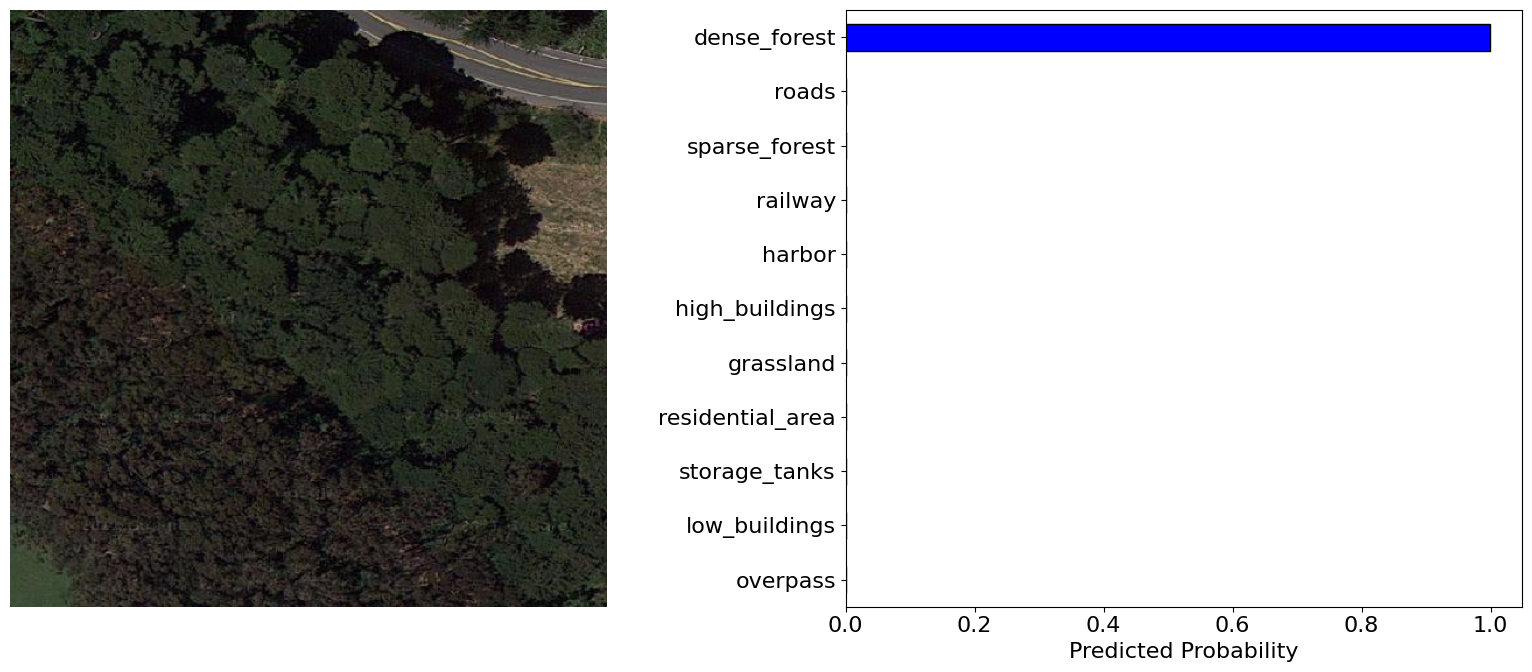

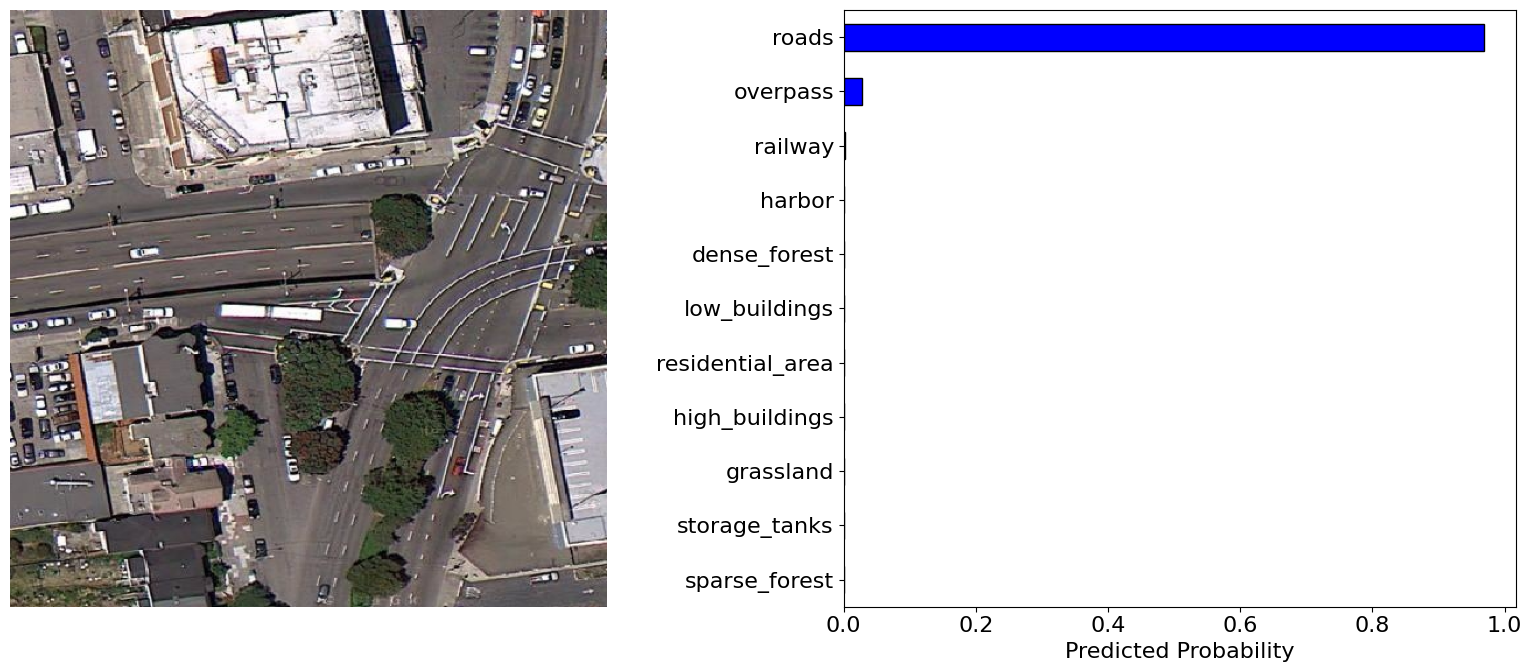

In [ ]:
labels = RSC11Dataset.labels
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/RSC11/1/best_checkpoint_1751980485_4.pth.tar"
model.load_model(model_path)

image, _ = test_dataset[7]
fig = model.predict_image(image, labels, transform)

image, _ = test_dataset[5]
fig = model.predict_image(image, labels, transform)